<a href="https://colab.research.google.com/github/Army-transportation-shin/Deep-Learning-For-Hackers/blob/master/notebooks/04.00-Introduction-To-Matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualization with Matplotlib

We'll now take an in-depth look at the Matplotlib package for visualization in Python.
Matplotlib is a multiplatform data visualization library built on NumPy arrays and designed to work with the broader SciPy stack.
It was conceived by John Hunter in 2002, originally as a patch to IPython for enabling interactive MATLAB-style plotting via `gnuplot` from the IPython command line.
IPython's creator, Fernando Perez, was at the time scrambling to finish his PhD, and let John know he wouldn’t have time to review the patch for several months.
John took this as a cue to set out on his own, and the Matplotlib package was born, with version 0.1 released in 2003.
It received an early boost when it was adopted as the plotting package of choice of the Space Telescope Science Institute (the folks behind the Hubble Telescope), which financially supported Matplotlib’s development and greatly expanded its capabilities.

One of Matplotlib’s most important features is its ability to play well with many operating systems and graphics backends.
Matplotlib supports dozens of backends and output types, which means you can count on it to work regardless of which operating system you are using or which output format you desire.
This cross-platform, everything-to-everyone approach has been one of the great strengths of Matplotlib.
It has led to a large user base, which in turn has led to an active developer base and Matplotlib’s powerful tools and ubiquity within the scientific Python world.

In recent years, however, the interface and style of Matplotlib have begun to show their age.
Newer tools like `ggplot` and `ggvis` in the R language, along with web visualization toolkits based on D3js and HTML5 canvas, often make Matplotlib feel clunky and old-fashioned.
Still, I'm of the opinion that we cannot ignore Matplotlib's strength as a well-tested, cross-platform graphics engine.
Recent Matplotlib versions make it relatively easy to set new global plotting styles (see [Customizing Matplotlib: Configurations and Style Sheets](04.11-Settings-and-Stylesheets.ipynb)), and people have been developing new packages that build on its powerful internals to drive Matplotlib via cleaner, more modern APIs—for example, Seaborn (discussed in [Visualization With Seaborn](04.14-Visualization-With-Seaborn.ipynb)), [`ggpy`](http://yhat.github.io/ggpy/), [HoloViews](http://holoviews.org/), and even Pandas itself can be used as wrappers around Matplotlib's API.
Even with wrappers like these, it is still often useful to dive into Matplotlib's syntax to adjust the final plot output.
For this reason, I believe that Matplotlib itself will remain a vital piece of the data visualization stack, even if new tools mean the community gradually moves away from using the Matplotlib API directly.

# General Matplotlib Tips

Before we dive into the details of creating visualizations with Matplotlib, there are a few useful things you should know about using the package.

## Importing Matplotlib

Just as we use the `np` shorthand for NumPy and the `pd` shorthand for Pandas, we will use some standard shorthands for Matplotlib imports:

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

The `plt` interface is what we will use most often, as you shall see throughout this part of the book.

## Setting Styles

We will use the `plt.style` directive to choose appropriate aesthetic styles for our figures.
Here we will set the `classic` style, which ensures that the plots we create use the classic Matplotlib style:

In [ ]:
plt.style.use('classic')

Throughout this chapter, we will adjust this style as needed.
For more information on stylesheets, see [Customizing Matplotlib: Configurations and Style Sheets](04.11-Settings-and-Stylesheets.ipynb).

## show or No show? How to Display Your Plots

A visualization you can't see won't be of much use, but just how you view your Matplotlib plots depends on the context.
The best use of Matplotlib differs depending on how you are using it; roughly, the three applicable contexts are using Matplotlib in a script, in an IPython terminal, or in a Jupyter notebook.

### Plotting from a Script

If you are using Matplotlib from within a script, the function `plt.show` is your friend.
`plt.show` starts an event loop, looks for all currently active `Figure` objects, and opens one or more interactive windows that display your figure or figures.

So, for example, you may have a file called *myplot.py* containing the following:

```python
# file: myplot.py
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 100)

plt.plot(x, np.sin(x))
plt.plot(x, np.cos(x))

plt.show()
```

You can then run this script from the command-line prompt, which will result in a window opening with your figure displayed:

```
$ python myplot.py
```

The `plt.show` command does a lot under the hood, as it must interact with your system's interactive graphical backend.
The details of this operation can vary greatly from system to system and even installation to installation, but Matplotlib does its best to hide all these details from you.

One thing to be aware of: the `plt.show` command should be used *only once* per Python session, and is most often seen at the very end of the script.
Multiple `show` commands can lead to unpredictable backend-dependent behavior, and should mostly be avoided.

### Plotting from an IPython Shell

Matplotlib also works seamlessly within an IPython shell (see [IPython: Beyond Normal Python](01.00-IPython-Beyond-Normal-Python.ipynb)).
IPython is built to work well with Matplotlib if you specify Matplotlib mode.
To enable this mode, you can use the `%matplotlib` magic command after starting `ipython`:

```ipython
In [1]: %matplotlib
Using matplotlib backend: TkAgg

In [2]: import matplotlib.pyplot as plt
```

At this point, any `plt` plot command will cause a figure window to open, and further commands can be run to update the plot.
Some changes (such as modifying properties of lines that are already drawn) will not draw automatically: to force an update, use `plt.draw`.
Using `plt.show` in IPython's Matplotlib mode is not required.

### Plotting from a Jupyter Notebook

The Jupyter notebook is a browser-based interactive data analysis tool that can combine narrative, code, graphics, HTML elements, and much more into a single executable document (see [IPython: Beyond Normal Python](01.00-IPython-Beyond-Normal-Python.ipynb)).

Plotting interactively within a Jupyter notebook can be done with the `%matplotlib` command, and works in a similar way to the IPython shell.
You also have the option of embedding graphics directly in the notebook, with two possible options:

- `%matplotlib inline` will lead to *static* images of your plot embedded in the notebook.
- `%matplotlib notebook` will lead to *interactive* plots embedded within the notebook.

For this book, we will generally stick with the default, with figures rendered as static images (see the following figure for the result of this basic plotting example):

\

In [1]:
%matplotlib inline

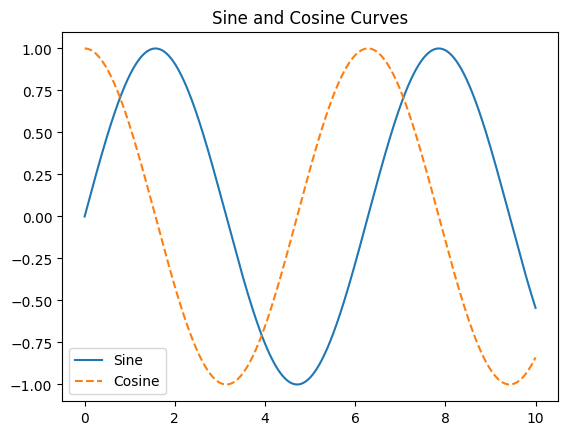

In [8]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 10, 10000)

fig = plt.figure()
plt.plot(x, np.sin(x), '-', label='Sine')
plt.plot(x, np.cos(x), '--', label='Cosine')

# 제목과 범례 추가
plt.title("Sine and Cosine Curves")
plt.legend();

In [6]:
s90 = np.sin(90)
c90 = np.cos(90)
print(s90, c90)

0.8939966636005579 -0.4480736161291701


In [7]:
import math

def degrees_to_radians(degrees):
    """
    60분법(도, Degrees)을 호도법(라디안, Radians)으로 변환하는 함수
    """
    return math.radians(degrees)

# 직접 수식(도 * pi / 180)으로 변환하는 방법
def degrees_to_radians_manual(degrees):
    return degrees * (math.pi / 180)

# 테스트 코드
test_deg = 180
print(f"{test_deg}도는 호도법으로 {degrees_to_radians(test_deg)} 라디안입니다. (pi = {math.pi})")

180도는 호도법으로 3.141592653589793 라디안입니다. (pi = 3.141592653589793)


In [ ]:
z = np.

### NumPy에서 복소수(Complex Number) 표현하기

파이썬 및 NumPy에서는 허수 단위로 `i` 대신 **`j`**를 사용합니다.
복소수 배열을 생성할 때는 다음과 같은 방법을 사용할 수 있습니다.

In [1]:
import numpy as np

# 1. 'j' 표기법을 사용하여 직접 복소수 배열 생성
z1 = np.array([1 + 2j, 3 - 4j, 5j])
print("복소수 배열 z1:", z1)
print("z1의 타입:", z1.dtype)

# 2. dtype을 complex로 명시하여 생성
z2 = np.array([1, 2, 3], dtype=complex)
print("실수를 복소수형으로 변환한 z2:", z2)

# 3. 복소수의 실수부(real)와 허수부(imag) 추출 및 켤레복소수(conj)
print("z1의 실수부:", z1.real)
print("z1의 허수부:", z1.imag)
print("z1의 켤레복소수:", z1.conj())

복소수 배열 z1: [1.+2.j 3.-4.j 0.+5.j]
z1의 타입: complex128
실수를 복소수형으로 변환한 z2: [1.+0.j 2.+0.j 3.+0.j]
z1의 실수부: [1. 3. 0.]
z1의 허수부: [ 2. -4.  5.]
z1의 켤레복소수: [1.-2.j 3.+4.j 0.-5.j]


In [2]:
import sympy as sp

# 1. 기호 변수 정의
t = sp.Symbol('t', real=True)

# 2. 벡터 r(t) 정의 (i, j, k 성분을 열벡터로 표현)
r = sp.Matrix([
    t**2 + 2*t,
    -3 * sp.exp(2*t),
    2 * sp.sin(t)
])

# (1) dr/dt 계산 및 t=0 대입
dr_dt = r.diff(t)
dr_dt_0 = dr_dt.subs(t, 0)

# (2) |dr/dt| at t=0 계산 (크기/절댓값)
norm_dr_dt_0 = dr_dt_0.norm()

# (3) d^2r/dt^2 계산 및 t=0 대입
d2r_dt2 = r.diff(t, 2)
d2r_dt2_0 = d2r_dt2.subs(t, 0)

# (4) |d^2r/dt^2| at t=0 계산
norm_d2r_dt2_0 = d2r_dt2_0.norm()

# 결과 출력
print("(1) dr/dt at t=0     :", dr_dt_0.T)
print("(2) |dr/dt| at t=0   :", norm_dr_dt_0)
print("(3) d^2r/dt^2 at t=0 :", d2r_dt2_0.T)
print("(4) |d^2r/dt^2| at t=0:", norm_d2r_dt2_0)

(1) dr/dt at t=0     : Matrix([[2, -6, 2]])
(2) |dr/dt| at t=0   : 2*sqrt(11)
(3) d^2r/dt^2 at t=0 : Matrix([[2, -12, 0]])
(4) |d^2r/dt^2| at t=0: 2*sqrt(37)


In [21]:
a = np.complex64(1,np.sqrt(3))
b= np.power(a,6)
print(b)

(64+0j)


In [24]:
ans = np.sin(-690)*np.cos(75)
print(ans)

0.8414857649114577


In [27]:
mat = np.array([[1,1,1],[1,-2,4],[2,-5,-1]])
mat_dot = np.dot(mat)
print(mat_dot)

TypeError: dot() missing 1 required positional argument: 'b'

### Saving Figures to File

One nice feature of Matplotlib is the ability to save figures in a wide variety of formats.
Saving a figure can be done using the `savefig` command.
For example, to save the previous figure as a PNG file, we can run this:

In [ ]:
fig.savefig('my_figure.png')

We now have a file called *my_figure.png* in the current working directory:

In [ ]:
!ls -lh my_figure.png

-rw-r--r--  1 jakevdp  staff    26K Feb  1 06:15 my_figure.png


To confirm that it contains what we think it contains, let's use the IPython `Image` object to display the contents of this file (see the following figure):

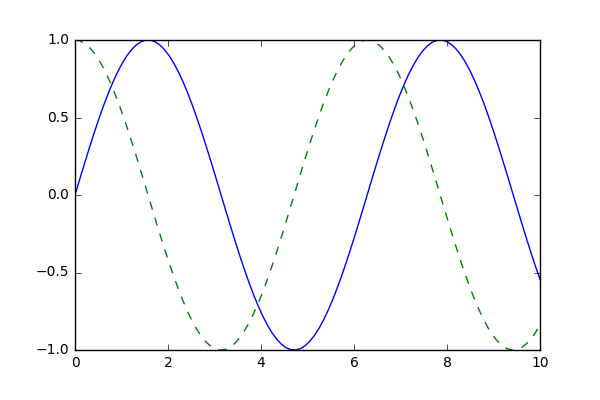

In [ ]:
from IPython.display import Image
Image('my_figure.png')

In `savefig`, the file format is inferred from the extension of the given filename.
Depending on what backends you have installed, many different file formats are available.
The list of supported file types can be found for your system by using the following method of the figure canvas object:

In [ ]:
fig.canvas.get_supported_filetypes()

{'eps': 'Encapsulated Postscript',
 'jpg': 'Joint Photographic Experts Group',
 'jpeg': 'Joint Photographic Experts Group',
 'pdf': 'Portable Document Format',
 'pgf': 'PGF code for LaTeX',
 'png': 'Portable Network Graphics',
 'ps': 'Postscript',
 'raw': 'Raw RGBA bitmap',
 'rgba': 'Raw RGBA bitmap',
 'svg': 'Scalable Vector Graphics',
 'svgz': 'Scalable Vector Graphics',
 'tif': 'Tagged Image File Format',
 'tiff': 'Tagged Image File Format'}

Note that when saving your figure, it is not necessary to use `plt.show` or related commands discussed earlier.

### Two Interfaces for the Price of One

A potentially confusing feature of Matplotlib is its dual interfaces: a convenient MATLAB-style state-based interface, and a more powerful object-oriented interface. I'll quickly highlight the differences between the two here.

#### MATLAB-style Interface

Matplotlib was originally conceived as a Python alternative for MATLAB users, and much of its syntax reflects that fact.
The MATLAB-style tools are contained in the `pyplot` (`plt`) interface.
For example, the following code will probably look quite familiar to MATLAB users (the following figure shows the result):

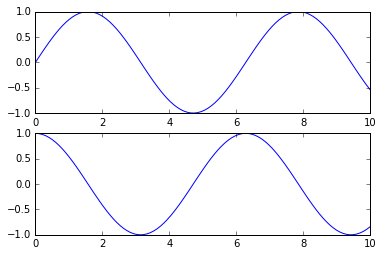

In [ ]:
plt.figure()  # create a plot figure

# create the first of two panels and set current axis
plt.subplot(2, 1, 1) # (rows, columns, panel number)
plt.plot(x, np.sin(x))

# create the second panel and set current axis
plt.subplot(2, 1, 2)
plt.plot(x, np.cos(x));

It is important to recognize that this interface is *stateful*: it keeps track of the "current" figure and axes, which are where all `plt` commands are applied.
You can get a reference to these using the `plt.gcf` (get current figure) and `plt.gca` (get current axes) routines.

While this stateful interface is fast and convenient for simple plots, it is easy to run into problems.
For example, once the second panel is created, how can we go back and add something to the first?
This is possible within the MATLAB-style interface, but a bit clunky.
Fortunately, there is a better way.

#### Object-oriented interface

The object-oriented interface is available for these more complicated situations, and for when you want more control over your figure.
Rather than depending on some notion of an "active" figure or axes, in the object-oriented interface the plotting functions are *methods* of explicit `Figure` and `Axes` objects.
To re-create the previous plot using this style of plotting, as shown in the following figure, you might do the following:

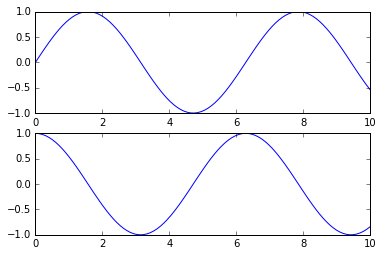

In [ ]:
# First create a grid of plots
# ax will be an array of two Axes objects
fig, ax = plt.subplots(2)

# Call plot() method on the appropriate object
ax[0].plot(x, np.sin(x))
ax[1].plot(x, np.cos(x));

For simpler plots, the choice of which style to use is largely a matter of preference, but the object-oriented approach can become a necessity as plots become more complicated.
Throughout the following chapters, we will switch between the MATLAB-style and object-oriented interfaces, depending on what is most convenient.
In most cases, the difference is as small as switching `plt.plot` to `ax.plot`, but there are a few gotchas that I will highlight as they come up in the following chapters.